In [1]:
#TODO: Comentar todo el cuaderno lo más profundamente
#Importación de librerías
#numpy fundamental para gestión de arrays N-dimensionales 
import numpy as np
#scipy para cálculo numérico, álgebra lineal, etc. Ambos básicos para computación científica
import scipy as sc
#matplotlib Gráficas
import matplotlib.pyplot as plt
#https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_circles.html Permite dibujar un par de círculos
from sklearn import datasets

ModuleNotFoundError: No module named 'numpy'

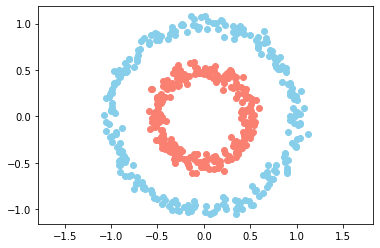

In [12]:
# CREAR EL DATASET

n = 500 
p = 2 

X, Y = datasets.make_circles(n_samples=n, factor=0.5, noise=0.05)

#TODO: Probar con este otro dataset
#X, Y = datasets.make_moons(n_samples=n, noise=0.05)

Y = Y[:, np.newaxis]

plt.scatter(X[Y[:, 0] == 0, 0], X[Y[:, 0] == 0, 1], c="skyblue")
plt.scatter(X[Y[:, 0] == 1, 0], X[Y[:, 0] == 1, 1], c="salmon")
plt.axis("equal")
plt.show()

In [13]:
# CLASE DE LA CAPA DE LA RED

class neural_layer():
 
  def __init__(self, n_conn, n_neur, act_f): 
    self.act_f = act_f
    
    self.b = np.random.rand(1, n_neur)      * 2 - 1
    self.W = np.random.rand(n_conn, n_neur) * 2 - 1

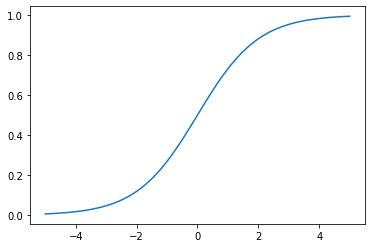

In [18]:
# FUNCIONES DE ACTIVACION

sigm = (lambda x: 1 / (1 + np.e ** (-x)), 
        lambda x: x * (1 - x))

relu = lambda x: np.maximum(0, x)

_x = np.linspace(-5, 5, 100)
plt.plot(_x, sigm[0](_x))
#plt.plot(_x, sigm[1](_x)) #Para visualizar la derivada
# TODO: Crear nuevas funciones de activiación así como sus derivadas (en relu no hemos incluido la derivada)

In [7]:
# CREAMOS LA RED NEURONAL

l0 = neural_layer(p, 4, sigm)
l1 = neural_layer(4, 8, sigm)
# ...

def create_nn(topology, act_f):
  
  nn = []
  
  for l, layer in enumerate(topology[:-1]): 
     
    nn.append(neural_layer(topology[l], topology[l+1], act_f)) #OJO: Las eles aparecen en negro y los unos en verde
    
  return nn

In [8]:
# FUNCION DE ENTRENAMIENTO
topology = [p, 4, 8, 1]

neural_net=create_nn(topology, sigm)

l2_cost = (lambda Yp, Yr: np.mean((Yp - Yr) ** 2), 
           lambda Yp, Yr: (Yp - Yr))  

def train(neural_net, X, Y, l2_cost, lr=0.5, train=True): 

  out = [(None, X)]
  
  # Forward pass
  for l, layer in enumerate(neural_net):
    
    z = out[-1][1] @ neural_net[l].W + neural_net[l].b #OJO: Las eles aparecen en negro y los unos en verde
    a = neural_net[l].act_f[0](z)
  
    out.append((z, a))
    
  
  if train:
    
    # Backward pass 
    deltas = []
    
    for l in reversed(range(0, len(neural_net))):
      
      z = out[l+1][0]
      a = out[l+1][1]
      
      if l == len(neural_net) - 1:
        deltas.insert(0, l2_cost[1](a, Y) * neural_net[l].act_f[1](a))
      else:
        deltas.insert(0, deltas[0] @ _W.T * neural_net[l].act_f[1](a))
       
      _W = neural_net[l].W
 
      # Gradient descent
      neural_net[l].b = neural_net[l].b - np.mean(deltas[0], axis=0, keepdims=True) * lr   
      neural_net[l].W = neural_net[l].W - out[l][1].T @ deltas[0] * lr
      
  return out[-1][1]
  



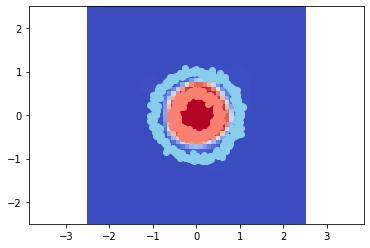

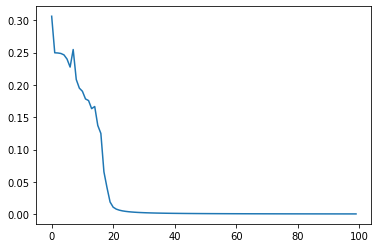

In [9]:
# VISUALIZACIÓN Y TEST

import time
from IPython.display import clear_output
act_f=sigm
#topology=[p,8,4,1] Otra posible topología lo normal es pasar de más a menos neuronas por capa
neural_n = create_nn(topology, act_f)

loss = []

for i in range(2500):
    
  # Entrenemos a la red!
  pY = train(neural_n, X, Y, l2_cost, lr=0.05)
  
  if i % 25 == 0:
    
    print(pY)
  
    loss.append(l2_cost[0](pY, Y))
  
    res = 50

    _x0 = np.linspace(-1.5, 1.5, res)
    _x1 = np.linspace(-1.5, 1.5, res)

    _Y = np.zeros((res, res))

    for i0, x0 in enumerate(_x0):
      for i1, x1 in enumerate(_x1):
        _Y[i0, i1] = train(neural_n, np.array([[x0, x1]]), Y, l2_cost, train=False)[0][0]    

    plt.pcolormesh(_x0, _x1, _Y, cmap="coolwarm")
    plt.axis("equal")

    plt.scatter(X[Y[:,0] == 0, 0], X[Y[:,0] == 0, 1], c="skyblue")
    plt.scatter(X[Y[:,0] == 1, 0], X[Y[:,0] == 1, 1], c="salmon")

    clear_output(wait=True)
    plt.show()
    plt.plot(range(len(loss)), loss)
    plt.show()
    #time.sleep(0.5)  #por si queremos ver los pasos poco a poco